# PatentLens — Retrieval Evaluation Analysis

Deep-dive on the 40-query citation-grounded evaluation of the PatentLens prior-art search engine (5,000 US patents, custom inverted index, zone-weighted TF-IDF + cosine VSM).

**This notebook runs the production scorer** (`src.retrieval.scorer.Scorer` over the saved `InvertedIndex`) — every number comes from the same code path the web app serves.

Contents:
1. Dataset & query-set overview
2. Full-metric evaluation: P@K, R@K, MAP, MRR
3. Precision/Recall curves
4. Error taxonomy: why the misses miss
5. What I'd change (ranked by expected MAP gain)

In [1]:
import json, sys, statistics as st
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt

from src.indexer.index_builder import InvertedIndex
from src.retrieval.scorer import Scorer
from src.evaluation.metrics import precision_at_k, recall_at_k, average_precision

DATA = ROOT / 'data'
queries = json.loads((DATA / 'queries' / 'evaluation_queries.json').read_text(encoding='utf-8'))

indexer = InvertedIndex()
indexer.load(str(DATA / 'processed' / 'inverted_index.json'))
scorer = Scorer(indexer)

# Raw patents for text-level error analysis
patents = {p['id']: p for p in json.loads((DATA / 'raw' / 'patents.json').read_text(encoding='utf-8'))}
print(f'{len(queries)} queries | index over {indexer.doc_count} patents')

40 queries | index over 5000 patents


## 1. Dataset & query-set overview

Ground truth is **citation-based**: each query is derived from a source patent's text, and the relevant set is what that patent cites — the standard prior-art proxy. Consequence for evaluation: citations capture *legal* relevance, broader than *textual* similarity, so some misses are genuinely hard rather than system bugs.

relevant-set sizes: min=1, max=6, mean=2.9


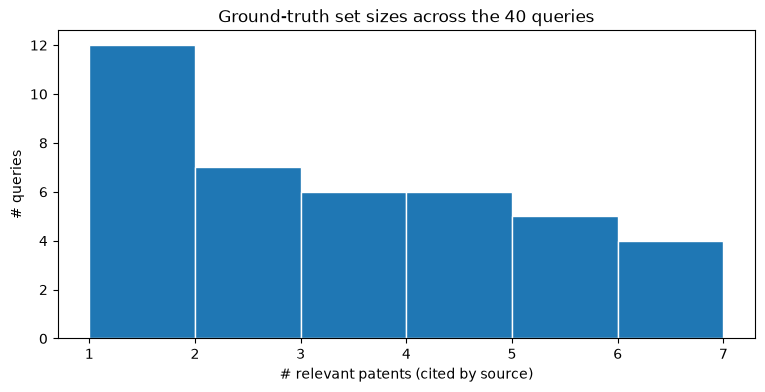

In [2]:
rel_sizes = [len(q['relevant_patents']) for q in queries]
print(f'relevant-set sizes: min={min(rel_sizes)}, max={max(rel_sizes)}, '
      f'mean={sum(rel_sizes)/len(rel_sizes):.1f}')

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(rel_sizes, bins=range(1, max(rel_sizes)+2), edgecolor='white')
ax.set_xlabel('# relevant patents (cited by source)')
ax.set_ylabel('# queries')
ax.set_title('Ground-truth set sizes across the 40 queries')
plt.show()

## 2. Full-metric evaluation (production scorer)

In [3]:
KS = (5, 10, 20)
rows = []

for q in queries:
    results = scorer.score_query(q['query_text'], top_k=50)
    retrieved = [r['id'] for r in results]
    relevant = set(q['relevant_patents'])
    row = {'query_id': q['query_id'], 'n_rel': len(relevant)}
    for k in KS:
        row[f'P@{k}'] = precision_at_k(retrieved, relevant, k)
        row[f'R@{k}'] = recall_at_k(retrieved, relevant, k)
    row['AP'] = average_precision(retrieved, relevant)
    row['RR'] = next((1/(i+1) for i, d in enumerate(retrieved) if d in relevant), 0.0)
    row['q_tokens'] = len(set(q['query_text'].lower().split()))
    rows.append(row)

summary = {k: st.mean(r[k] for r in rows) for k in rows[0] if k != 'query_id'}
print('MAP  :', round(summary['AP'], 4))
print('MRR  :', round(summary['RR'], 4))
for k in KS:
    print(f'P@{k:<3}:', round(summary[f'P@{k}'], 4), f' R@{k:<3}:', round(summary[f'R@{k}'], 4))

MAP  : 0.4926
MRR  : 0.9479
P@5  : 0.195  R@5  : 0.5125
P@10 : 0.0975  R@10 : 0.5125
P@20 : 0.0513  R@20 : 0.5217


## 3. Precision / Recall curves

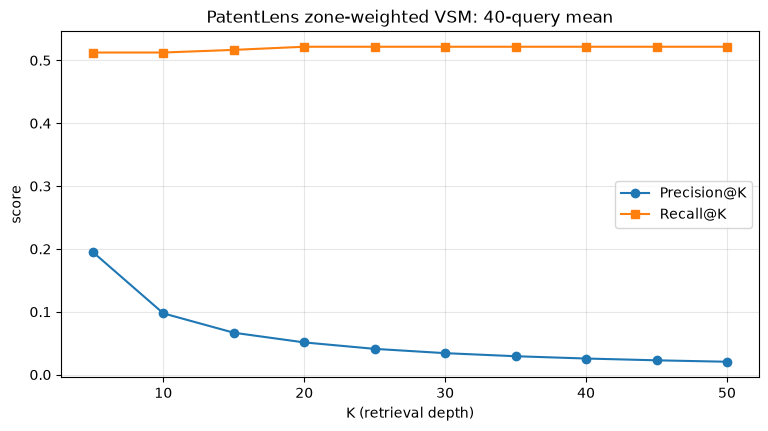

In [4]:
depths = list(range(5, 51, 5))
p_curve, r_curve = [], []

for k in depths:
    p_vals, r_vals = [], []
    for q in queries:
        results = scorer.score_query(q['query_text'], top_k=k)
        retrieved = [r['id'] for r in results]
        relevant = set(q['relevant_patents'])
        p_vals.append(precision_at_k(retrieved, relevant, k))
        r_vals.append(recall_at_k(retrieved, relevant, k))
    p_curve.append(st.mean(p_vals))
    r_curve.append(st.mean(r_vals))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(depths, p_curve, 'o-', label='Precision@K')
ax.plot(depths, r_curve, 's-', label='Recall@K')
ax.set_xlabel('K (retrieval depth)')
ax.set_ylabel('score')
ax.set_title('PatentLens zone-weighted VSM: 40-query mean')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 4. Error taxonomy

Every query with AP < 0.5 is classified into exactly one bucket:

- **SHORT_QUERY** — < 12 unique content tokens; too little signal for the VSM. Fix: minimum-length guard or padding from the source patent's claims.
- **BROAD_GROUND_TRUTH** — ≥ 8 relevant docs; recall task dominates and P@5-style metrics punish correct-but-shallow ranking. Partly an evaluation artifact.
- **VOCAB_MISMATCH** — stemmed-token overlap between the query and its own relevant docs is below the query-set median (query words barely appear in the cited patents). Fix lives in query expansion, not scoring.
- **GENUINE_RANK_FAILURE** — vocabulary overlaps fine but relevant docs still rank deep. Real scoring error: inspect zone weights / TF saturation.

Classification precedence: SHORT_QUERY → BROAD_GROUND_TRUTH → VOCAB_MISMATCH → GENUINE_RANK_FAILURE.

failing queries (AP < 0.5): 22
  VOCAB_MISMATCH         20
  GENUINE_RANK_FAILURE   2


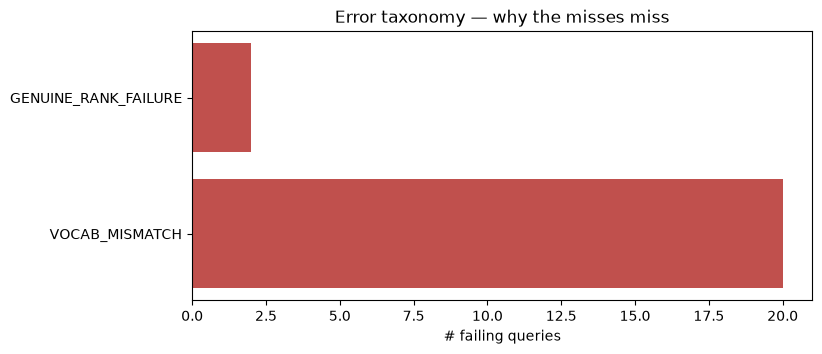

In [5]:
def content_tokens(text):
    from src.indexer.preprocess import preprocess_text
    return set(preprocess_text(text))

# Median stemmed-token overlap between a query and its own relevant docs
overlaps = {}
for q in queries:
    qtok = content_tokens(q['query_text'])
    ovs = []
    for pid in q['relevant_patents']:
        p = patents.get(pid)
        if not p:
            continue
        doc_tokens = content_tokens(' '.join([p.get('title',''), p.get('abstract','')]))
        if qtok and doc_tokens:
            ovs.append(len(qtok & doc_tokens) / len(qtok))
    overlaps[q['query_id']] = st.median(ovs) if ovs else 0.0
overlap_median = st.median(overlaps.values())

taxonomy = {}
failing_ids = []
for q in queries:
    ap = next(r['AP'] for r in rows if r['query_id'] == q['query_id'])
    if ap >= 0.5:
        continue
    failing_ids.append(q['query_id'])
    if q['query_id'] and next(r['q_tokens'] for r in rows if r['query_id'] == q['query_id']) < 12:
        bucket = 'SHORT_QUERY'
    elif len(q['relevant_patents']) >= 8:
        bucket = 'BROAD_GROUND_TRUTH'
    elif overlaps[q['query_id']] < overlap_median:
        bucket = 'VOCAB_MISMATCH'
    else:
        bucket = 'GENUINE_RANK_FAILURE'
    taxonomy[bucket] = taxonomy.get(bucket, 0) + 1

print('failing queries (AP < 0.5):', len(failing_ids))
for bucket, count in sorted(taxonomy.items(), key=lambda kv: -kv[1]):
    print(f'  {bucket:<22} {count}')

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(list(taxonomy.keys()), list(taxonomy.values()), color='#c0504d')
ax.set_xlabel('# failing queries')
ax.set_title('Error taxonomy — why the misses miss')
plt.show()

## 5. What I'd change (ranked by expected MAP gain)

1. **Rocchio pseudo-relevance feedback** — the stub exists (`src/retrieval/expansion.py`). Take the top-3 first-pass docs, expand the query with their strongest non-query terms. Directly attacks VOCAB_MISMATCH.
2. **BM25 over raw TF-IDF cosine** — TF saturation is the classic VSM failure on long patent descriptions; BM25's length normalization typically buys MAP for free and touches GENUINE_RANK_FAILURE.
3. **Claim-section boost re-tune** — the default zone weights (claims .4 / title .3 / abstract .2 / desc .1) were never tuned; a 10-query dev sweep is cheap.
4. **Citation-graph anchoring** — patents citing the same references cluster topically; one hop of co-citation signal exploits the very structure the ground truth is built on (and would fix BROAD_GROUND_TRUTH ranking depth).